In [1]:
import pandas as pd

df = pd.read_csv("sales_data.csv")

dates = ["order_date", "shipping_date", "delivery_date"]
for col in dates:
    df[col] = pd.to_datetime(df[col])

df.shape

(1030, 14)

In [2]:
before = len(df)
df = df.drop_duplicates()
print(before, "->", len(df))

1030 -> 1004


In [3]:
bad = df["quantity"] > 100
df.loc[bad, "quantity"] = (df.loc[bad, "total_sales"] / df.loc[bad, "unit_price"]).round().astype(int)
diff = (df["total_sales"] - df["quantity"] * df["unit_price"]).abs()
print("고친 줄 :", bad.sum(), " 수량 최대 :", df["quantity"].max(), " 총액 안 맞는 줄 :", (diff > 1).sum())

고친 줄 : 22  수량 최대 : 99  총액 안 맞는 줄 : 0


In [4]:
df["date_error"] = df["delivery_date"] < df["shipping_date"]
df["date_error"].value_counts()
df.to_csv("sales_clean.csv", index=False)
print(df["date_error"].sum(), "건,", df.shape)

147 건, (1004, 15)


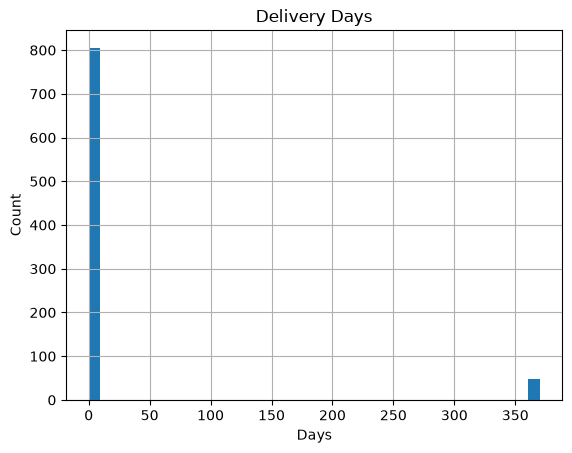

평균: 22.05
중앙값: 2.0
300일 초과 건수: 47
300일 초과 범위: 364.0 ~ 370.0


In [5]:
import matplotlib.pyplot as plt


days = (df.loc[~df["date_error"], "delivery_date"]
        - df.loc[~df["date_error"], "shipping_date"]).dt.days

days.hist(bins=40)
plt.title("Delivery Days")
plt.xlabel("Days")
plt.ylabel("Count")
plt.show()

print("평균:", round(days.mean(), 2))
print("중앙값:", days.median())
print("300일 초과 건수:", (days > 300).sum())
print("300일 초과 범위:", days[days > 300].min(),
      "~", days[days > 300].max())

결과: 평균 22.05일, 중앙값 2일이며, 364~370일의 극단적인 배송 기간이 존재한다.

해석: 약 1년의 배송 기간이 평균을 높이므로 중앙값 2일이 일반적인 배송 기간을 더 잘 나타낸다. 장기 배송 기록은 입력 오류 가능성이 있어 별도 표시하고 일반 배송 기간 분석에서 제외하는 것이 적절하다.

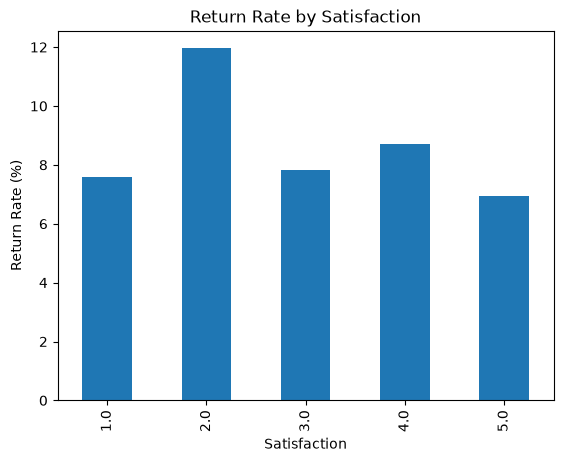

satisfaction
1.0     7.59
2.0    11.96
3.0     7.81
4.0     8.72
5.0     6.93
Name: status, dtype: float64


In [6]:
return_rate = (
    df["status"].eq("반품")
    .groupby(df["satisfaction"])
    .mean() * 100
)

return_rate.plot.bar()
plt.title("Return Rate by Satisfaction")
plt.xlabel("Satisfaction")
plt.ylabel("Return Rate (%)")
plt.show()

print(return_rate.round(2))

결과: 만족도별 반품률은 1점 7.59%, 2점 11.96%, 3점 7.81%, 4점 8.72%, 5점 6.93%이다.

해석: 만족도가 높아져도 반품률이 일관되게 감소하지 않으므로, 만족도가 낮을수록 반품이 많다는 명확한 관계는 확인되지 않는다.

In [7]:
result = df.groupby("category").agg(
    주문건수=("total_sales", "size"),
    총매출=("total_sales", "sum"),
    평균단가=("unit_price", "mean"),
    평균수량=("quantity", "mean")
)

print(result.sort_values("총매출", ascending=False))

          주문건수           총매출           평균단가       평균수량
category                                              
가구         213  2.843337e+09  257322.909061  51.042254
식품         210  2.513274e+09  255232.928143  47.314286
전자제품       207  2.471628e+09  249651.606135  47.961353
도서         204  2.453240e+09  238500.636765  49.495098
의류         170  2.181904e+09  249447.162235  51.611765


In [8]:
df["date_error"] = df["delivery_date"] < df["shipping_date"]
df["date_error"].value_counts()
df.to_csv("sales_clean.csv", index=False)
print(df["date_error"].sum(), "건,",df.shape)

147 건, (1004, 15)


결과: 가구가 총매출 약 28.43억 원으로 1위이며 주문 건수 213건, 평균 단가 약 25.73만 원, 평균 수량 51.04개이다.

해석: 가구는 주문 건수와 평균 단가가 모두 가장 높고 평균 수량도 높은 편이어서, 세 요소가 함께 매출 1위에 기여한 것으로 판단된다.